# **실습 개요**

여러분은 와인 감정 스타트업의 데이터 분석팀에 합류했습니다. <br>
이 회사는 와인의 화학 성분 분석 결과만으로 와인의 포도 품종(Cabernet Sauvignon / Merlot / Pinot Noir)을 <br>
자동으로 판별하는 모델을 만들어, 와이너리의 품질 관리 및 블라인드 테이스팅 검증에 활용하려고 합니다.

## **데이터셋 설명**

와인 1,120병에 대한 화학 성분 분석 결과와 실제 포도 품종(정답)을 담은 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| alcohol | 알코올 함량 (%) |
| malic_acid | 사과산 함량 (g/L) |
| ash | 회분 함량 (g/L) |
| alcalinity_of_ash | 회분의 알칼리도 |
| magnesium | 마그네슘 함량 (mg/L) |
| total_phenols | 총 페놀 함량 |
| flavanoids | 플라보노이드 함량 |
| nonflavanoid_phenols | 비플라보노이드 페놀 함량 |
| proanthocyanins | 프로안토시아닌 함량 |
| color_intensity | 색상 강도 |
| hue | 색조 |
| od280_od315 | 단백질 함량 추정 흡광도 비율 (OD280/OD315) |
| proline | 프롤린(아미노산) 함량 |
| oak_aged | 오크통 숙성 여부 (Yes/No) |
| variety | **[target]** 포도 품종 (Cabernet Sauvignon / Merlot / Pinot Noir) |

## **데이터셋 URL**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety.csv

## **1. 데이터 살펴보기**

**Q1. 데이터 불러오기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety.csv")
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,oak_aged,variety
0,11.785199,1.169833,2.306773,24.208038,89.593547,2.290849,2.108096,0.243616,1.100715,3.786747,1.169956,2.721544,624.712679,No,Merlot
1,11.122725,4.103022,2.469871,19.018421,84.185270,2.201615,1.719580,0.295145,1.493834,3.831402,0.750554,1.774096,550.372477,NaN,Merlot
2,12.315376,1.079129,1.386586,25.770385,90.590014,1.280029,1.166926,0.420398,0.948833,3.828069,1.199902,2.289818,698.951732,Yes,Merlot
3,12.724482,0.879105,2.524974,17.036320,101.330910,3.054305,2.804751,0.322099,1.730976,5.741020,1.369589,3.248187,1331.241565,Yes,Cabernet Sauvignon
4,12.141689,1.730578,1.572926,17.286193,74.038796,2.123239,1.928006,0.310430,0.769692,2.921799,1.291609,2.859367,705.963614,Yes,Merlot


**Q2. 데이터의 크기와 컬럼별 정보를 확인합니다.**

In [3]:
# code here
df.shape
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1120 entries, 0 to 1119
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   alcohol               1120 non-null   float64
 1   malic_acid            1076 non-null   float64
 2   ash                   1120 non-null   float64
 3   alcalinity_of_ash     1120 non-null   float64
 4   magnesium             1042 non-null   float64
 5   total_phenols         1120 non-null   float64
 6   flavanoids            1120 non-null   float64
 7   nonflavanoid_phenols  1120 non-null   float64
 8   proanthocyanins       1009 non-null   float64
 9   color_intensity       1120 non-null   float64
 10  hue                   950 non-null    float64
 11  od280_od315           1120 non-null   float64
 12  proline               1120 non-null   float64
 13  oak_aged              1065 non-null   str    
 14  variety               1120 non-null   str    
dtypes: float64(13), str(2)
memory us

**Q3. 수치형 컬럼들의 기술 통계량을 확인합니다.**

In [4]:
# code here
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
count,1120.000000,1076.000000,1120.000000,1120.000000,1042.000000,1120.000000,1120.000000,1120.000000,1009.000000,1120.000000,950.000000,1120.000000,1120.000000
mean,13.066331,2.392728,2.380684,19.429161,99.464946,2.261206,2.084462,0.359310,1.581669,5.260124,0.950130,2.239949,748.218360
std,0.743732,1.132270,0.268746,3.375890,13.667743,0.617484,0.591677,0.121769,0.564194,2.371496,0.232600,0.519387,325.478965
min,10.105443,0.010000,1.384772,9.610953,42.431242,0.631154,0.545046,0.010000,0.010000,0.010000,0.252342,1.000000,0.100000
25%,12.536712,1.661629,2.220090,17.169921,90.771697,1.750480,1.612300,0.274527,1.184345,3.397556,0.750700,1.802643,514.353543
50%,13.113841,2.294375,2.401088,19.488909,99.778662,2.280092,2.086256,0.347769,1.597912,5.010499,0.974036,2.328159,665.046603
75%,13.598016,2.986024,2.552149,21.743173,108.523987,2.779385,2.551304,0.431901,1.956663,6.638302,1.125602,2.643533,971.807935
max,15.156931,6.818836,3.232603,29.440284,150.495520,3.943020,3.736051,0.813198,4.015494,13.996794,1.747186,3.769422,2080.316615


## **2. 데이터 분석하기**

### **2-1. 데이터 탐색하기**

데이터를 분석하여 인사이트를 찾아내는 과정입니다.
- 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.
- 그리고 데이터를 이해하기 위한 여러 정보들을 찾아 csv 형태로 추출하여 채점 사이트에 제출합니다.


**colab에서 csv 파일 다운로드하기**
```
from google.colab import files
files.download("submission.csv")
```

**Q1. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 품종(variety)별 데이터의 개수를 찾아 주세요.

찾아낸 DataFrame 그대로 저장하여 제출합니다.

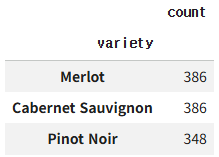

In [5]:
# code here
df["variety"].value_counts().to_csv("wine01.csv")

**Q2. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 품종(variety)별로 alcohol, flavanoids, color_intensity의 평균을 소수점 2자리까지 구해 비교해 주세요.

찾아낸 DataFrame 그대로 저장하여 제출합니다.

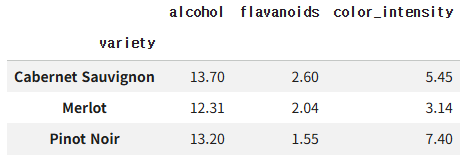

In [6]:
# code here
df.groupby("variety")[["alcohol", "flavanoids", "color_intensity"]].mean().round(2).to_csv("wine02.csv")

**Q3. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 먼저, 알코올 도수의 중앙값을 찾아주세요.
- 그리고 그 중앙값을 넘어가는 와인 품종별 비율을 찾아 주세요.
  - 즉, 도수가 높고 낮은 와인 품종을 비교합니다.

찾아낸 DataFrame 그대로 저장하여 제출합니다.

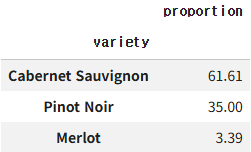

In [7]:
# code here
(df[df["alcohol"] > df["alcohol"].median()]["variety"].value_counts(normalize=True) * 100).round(2).to_csv("wine03.csv")

### **2-2. 데이터 시각화**

**Q1. alcohol 컬럼의 분포를 histogram으로 시각화하세요.**

- variety 별로 분해해서 볼 수 있도록 합니다.

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

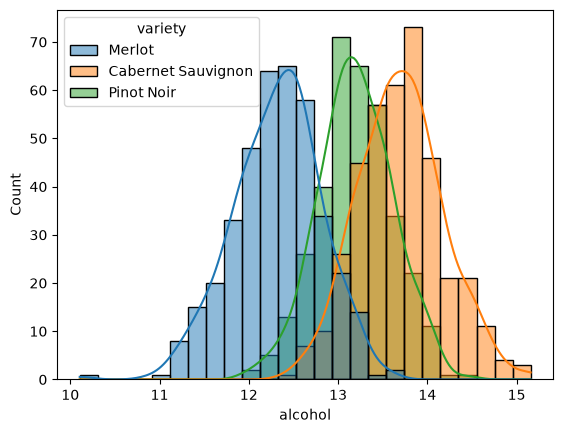

In [9]:
# code here

sns.histplot(df, x = "alcohol", kde = True, hue = "variety")
plt.show()

**Q1. 품종별 proline의 평균을 barplot으로 시각화하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

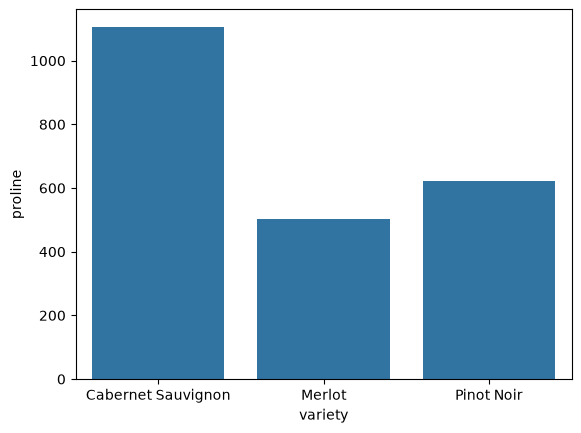

In [25]:
# code here
df_new = pd.DataFrame(df.groupby("variety")["proline"].mean())
df_new

sns.barplot(df_new, x=df_new.index, y="proline")
plt.show()

**Q3. 품종별 total_phenols를 막대그래프로 시각화하세요.**
- hue = oak_aged 그룹으로 나눕니다.

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

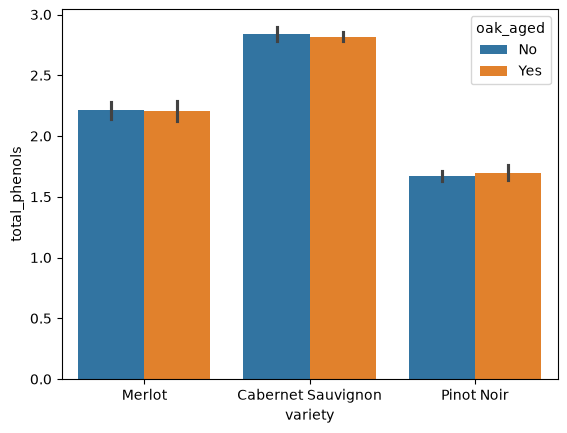

In [46]:
# code here
sns.barplot(df, x = "variety", y = "total_phenols", hue = "oak_aged")
plt.show()

**Q3. pairplot을 그려 수치형 컬럼들의 관계를 비교해 봅시다.**
- 품종별로 색을 다르게 시각화해주세요 (hue="variety')

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

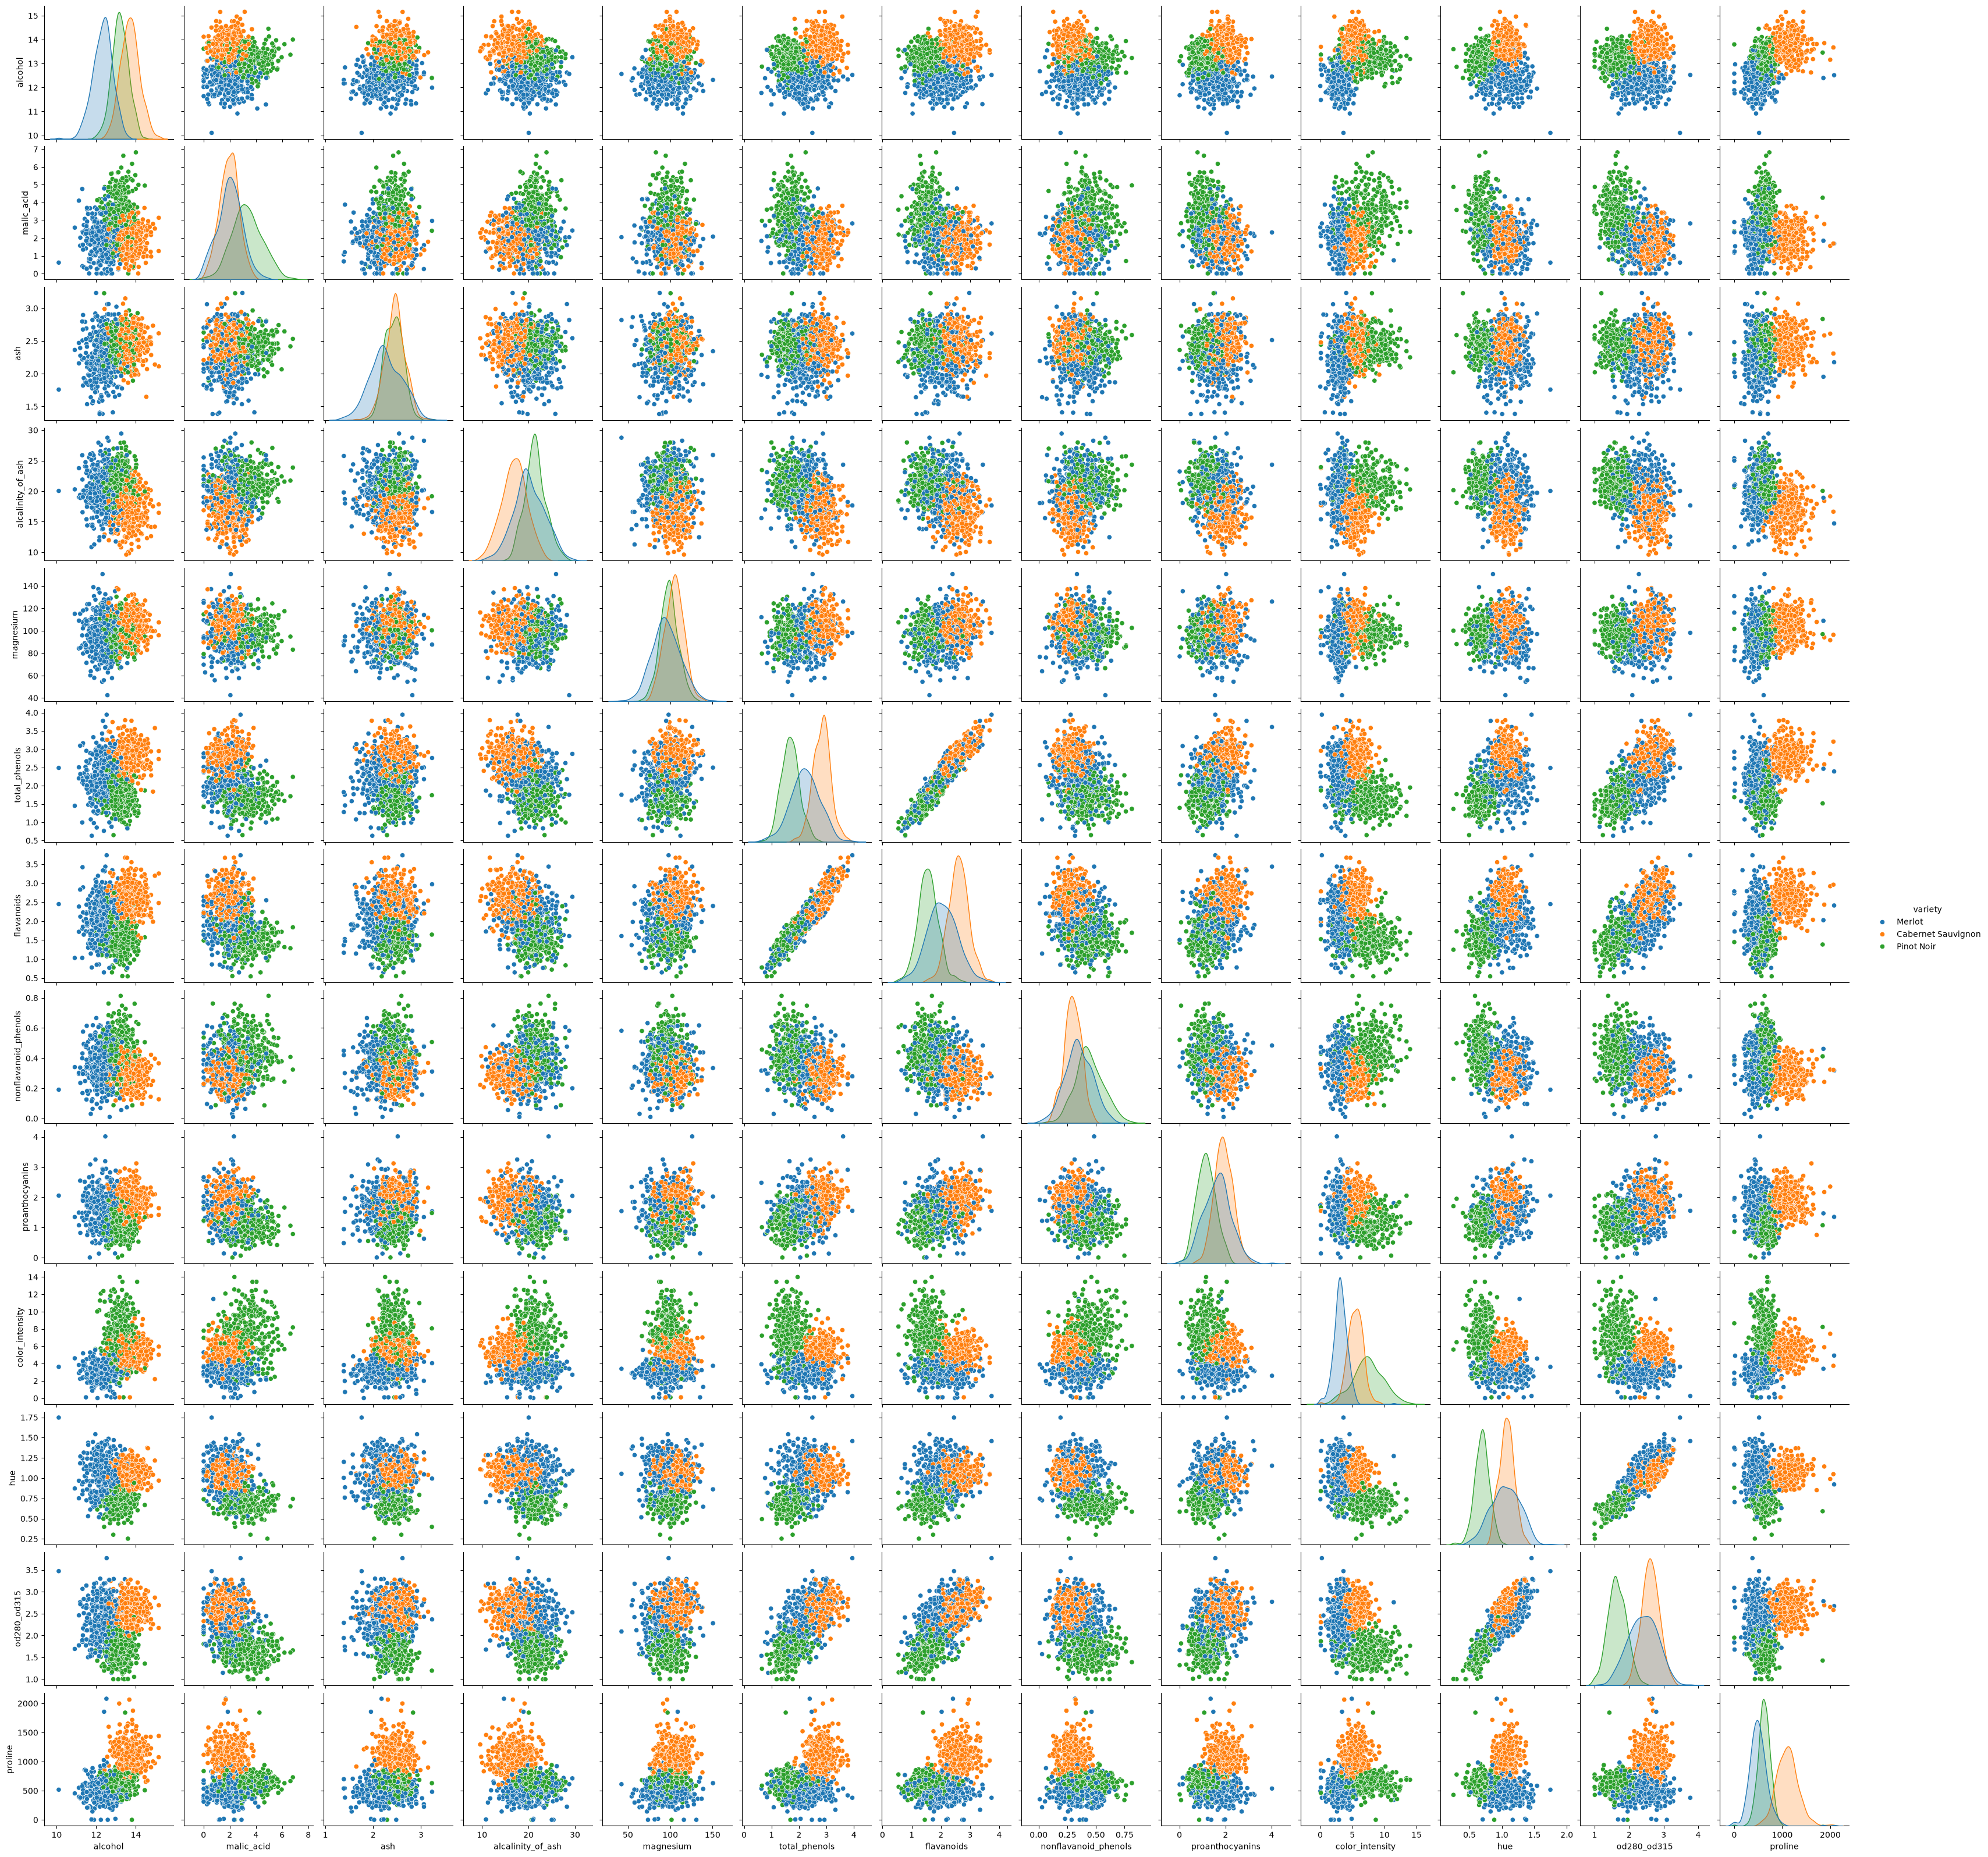

In [48]:
# code here
sns.pairplot(df, hue = "variety")
plt.show()

**Q4. Q3에서 찾은 관계가 있어보이는 특징 2개만 개별적으로 scatterplot으로 시각화해봅시다.**
- 품종별로 색을 다르게 시각화해주세요 (hue="variety')

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

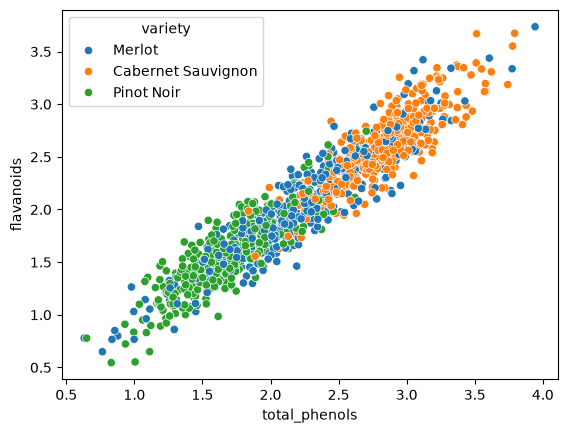

In [51]:
# code here
sns.scatterplot(df, x = "total_phenols", y = "flavanoids", hue = "variety")
plt.show()

<Axes: xlabel='hue', ylabel='od280_od315'>

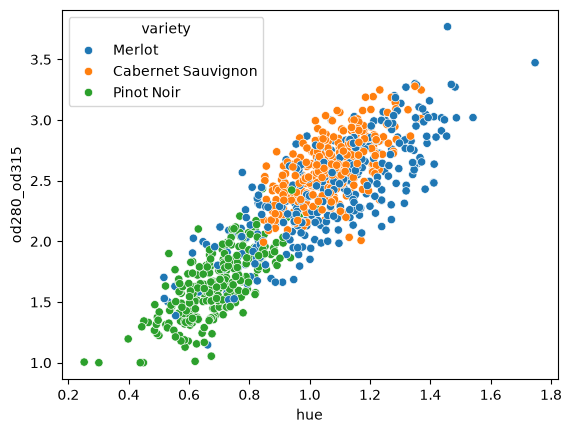

In [55]:
sns.scatterplot(df, x = "hue", y = "od280_od315", hue = "variety")

## **3. 데이터 전처리하기**

In [62]:
# 데이터 전처리 과정에서 데이터가 망가지면 여기서부터 다시 시작!
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety.csv")
df.shape

(1120, 15)

### **3-1. 중복 데이터 제거하기**

**Q1. 중복된 행이 몇 개 있는지 확인하세요.**

In [63]:
# code here
df.duplicated().sum()

np.int64(20)

**Q2. 중복된 행을 제거하세요.**

In [64]:
# code here
df.drop_duplicates()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,oak_aged,variety
0,11.785199,1.169833,2.306773,24.208038,89.593547,2.290849,2.108096,0.243616,1.100715,3.786747,1.169956,2.721544,624.712679,No,Merlot
1,11.122725,4.103022,2.469871,19.018421,84.185270,2.201615,1.719580,0.295145,1.493834,3.831402,0.750554,1.774096,550.372477,NaN,Merlot
2,12.315376,1.079129,1.386586,25.770385,90.590014,1.280029,1.166926,0.420398,0.948833,3.828069,1.199902,2.289818,698.951732,Yes,Merlot
3,12.724482,0.879105,2.524974,17.036320,101.330910,3.054305,2.804751,0.322099,1.730976,5.741020,1.369589,3.248187,1331.241565,Yes,Cabernet Sauvignon
4,12.141689,1.730578,1.572926,17.286193,74.038796,2.123239,1.928006,0.310430,0.769692,2.921799,1.291609,2.859367,705.963614,Yes,Merlot
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1115,13.393952,3.018532,2.400405,13.684010,108.463642,3.067946,3.010622,0.437482,2.590453,4.322681,1.138908,2.939299,1402.741437,No,Cabernet Sauvignon
1116,13.180008,2.916685,2.589782,11.200973,75.753564,3.203530,2.961507,0.290935,NaN,5.357166,1.047313,2.602117,950.275083,Yes,Cabernet Sauvignon
1117,13.328206,3.258316,2.839695,11.732019,94.300843,3.050789,2.321805,0.404825,2.194293,6.351594,1.023767,2.630057,864.729321,No,Cabernet Sauvignon
1118,12.096347,1.923107,2.200744,21.596019,86.686544,1.314884,1.103810,0.500583,1.891127,4.457778,1.382750,2.430383,634.242167,No,Merlot


### **3-2. 데이터 분리하기**

**Q1. 데이터를 학습 데이터와 테스트 데이터로 분리하세요.**
- 비율: 7(학습):3(테스트)
- random_state = 101

In [66]:
# code here
from sklearn.model_selection import train_test_split
X = df.drop("variety", axis = 1)
y = df["variety"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

### **3-3. 결측치 처리하기**

**Q1. train 데이터의 컬럼별 결측치 개수를 확인하세요.**

In [72]:
# code here
X_train.isnull().sum()

alcohol                   0
malic_acid               29
ash                       0
alcalinity_of_ash         0
magnesium                54
total_phenols             0
flavanoids                0
nonflavanoid_phenols      0
proanthocyanins          73
color_intensity           0
hue                     117
od280_od315               0
proline                   0
oak_aged                 42
dtype: int64

**Q2. malic_acid, magnesium, proanthocyanins, hue의 결측치를 train 데이터의 중앙값(median)으로 대체하세요.**
- 반드시 train 데이터의 통계량으로 test 데이터도 함께 처리해야 데이터 누수(data leakage)를 방지할 수 있습니다.

In [78]:
df[["malic_acid", "magnesium", "proanthocyanins", "hue"]]
fill_vals = df[["malic_acid", "magnesium", "proanthocyanins", "hue"]].median()
fill_vals

malic_acid          2.294375
magnesium          99.778662
proanthocyanins     1.597912
hue                 0.974036
dtype: float64

In [82]:
df[["malic_acid", "magnesium", "proanthocyanins", "hue"]] = df[["malic_acid", "magnesium", "proanthocyanins", "hue"]].fillna(fill_vals)

df.isnull().sum()

alcohol                  0
malic_acid               0
ash                      0
alcalinity_of_ash        0
magnesium                0
total_phenols            0
flavanoids               0
nonflavanoid_phenols     0
proanthocyanins          0
color_intensity          0
hue                      0
od280_od315              0
proline                  0
oak_aged                55
variety                  0
dtype: int64

In [ ]:
# code here
# miss_cols = df[df.isnull() == 1].columns
# miss_cols

Index(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
       'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue', 'od280_od315', 'proline',
       'oak_aged', 'variety'],
      dtype='str')

**Q3. 범주형 컬럼 oak_aged의 결측치를 train 데이터의 최빈값(mode)으로 대체하세요.**

In [87]:
# code here
fill_str = df["oak_aged"].mode()[0]
df["oak_aged"] = df["oak_aged"].fillna(fill_str)
df.isnull().sum()

alcohol                 0
malic_acid              0
ash                     0
alcalinity_of_ash       0
magnesium               0
total_phenols           0
flavanoids              0
nonflavanoid_phenols    0
proanthocyanins         0
color_intensity         0
hue                     0
od280_od315             0
proline                 0
oak_aged                0
variety                 0
dtype: int64

### **3-4. 이상치 처리하기**

**Q1. IQR을 활용하여 각 수치형 컬럼에 이상치가 몇 개씩 있는지 확인하세요.**

In [88]:
# outlier = 이상치
# 몇개가 있느냐? 좌측 whisker, 우측 whisker를 벗어나는 데이터의 개수
# 좌측 whisker : 25% * 1.5배까지 유예
# 우측 whisker : 75% * 1.5배까지 유예


# data: dataframe
# column: 이 dataframe의 어떤 열에 대해서 whisker를 찾으려고 하는지
def find_whiskers(data, column):
    #1. 25%, 75% quantile 찾기
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    #2. Inter Quntail Range구하기
    iqr = Q3 - Q1
    #3. 좌측 whisker와 우측 whisker를 구하기
    lower = Q1 - (1.5 * iqr)
    upper = Q3 + (1.5 * iqr)

    return (lower,upper)

In [89]:
# code here
# lower와 upper whisker를 dataframe 각각의 column마다 찾아낼 수 있음
# column에서 이 lower보다 작거나, upper보다 큰 값 -> 이상치

numeric_cols = X_train.select_dtypes(include = "number").columns

d = {} #key: 컬럼명, value : 튜플로 (lower, upper) <-한계치 이거보다 높거나 작은거는 채움

for c in numeric_cols:               #하나씩 열에 접근
    # lower, upper whisker를 만들어준 함수로 찾아옴
    lower, upper = find_whiskers(X_train, c)
    d[c] = (lower, upper)
    count = ((X_train[c] < lower) | (X_train[c] > upper)).sum() #lower보다 작거나 upper보다 큰 값 개수 세기
    print(f"{c} {count}개")
    # print(f"{c} : {lower}, {upper}")


alcohol 2개
malic_acid 20개
ash 20개
alcalinity_of_ash 4개
magnesium 11개
total_phenols 0개
flavanoids 0개
nonflavanoid_phenols 13개
proanthocyanins 4개
color_intensity 8개
hue 1개
od280_od315 0개
proline 7개


**Q2. 이상치 값들을 중앙값으로 clipping 합니다.**
- 반드시 train 데이터의 통계량으로 test 데이터도 함께 처리해야 데이터 누수(data leakage)를 방지할 수 있습니다.

In [90]:
# code here
# clip()
for c in numeric_cols:
    # 1. 우리가 찾아둔 lower, upper whisker를 가져옴
    lower, upper = d[c]
    X_train[c] = X_train[c].clip(lower,upper) # lower 보다 작은거는 lower, upper보다 작은 거는 upper
    # test_data에도 이상치가 있음. -> train 데이터의 lower와 upper whisker로 clipping
    X_test[c] = X_test[c].clip(lower, upper)

**Q3. 남아있는 이상치가 있는지 확인합니다.**

In [91]:
# code here
for c in numeric_cols:
    # 다시 find_whisker를 하면 또 이상치가 생길 수 있으므로.
    count = ((X_train[c] < d[c][0]) | (X_train[c] > d[c][1])).sum()
    print(f"{c} : {count}개")

alcohol : 0개
malic_acid : 0개
ash : 0개
alcalinity_of_ash : 0개
magnesium : 0개
total_phenols : 0개
flavanoids : 0개
nonflavanoid_phenols : 0개
proanthocyanins : 0개
color_intensity : 0개
hue : 0개
od280_od315 : 0개
proline : 0개


### **3-5. Feature Encoding**

**Q1. oak_aged 컬럼을 인코딩하세요**

In [93]:
# code 
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
X_train["oak_aged"] = le.fit_transform(X_train["oak_aged"])
X_test["oak_aged"] = le.transform(X_test["oak_aged"])

X_train

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,oak_aged
1037,12.872995,2.019267,2.095606,23.827861,107.412074,2.553754,2.302996,0.488981,1.818709,3.631174,1.392823,3.020088,379.298003,1
560,11.542553,1.980111,2.100813,14.385011,105.772910,2.421378,1.985425,0.361761,0.751892,1.789784,1.240946,2.643456,383.725580,1
795,11.756732,2.415156,1.815568,25.108719,110.669808,2.062847,2.038319,0.537364,2.014769,3.397824,0.822099,1.949491,828.972130,1
1084,14.263621,2.321570,2.747138,15.596292,93.186891,1.887337,1.555753,0.260138,2.094079,5.409074,1.071787,2.325024,1060.989672,0
930,13.482499,4.581738,2.284135,24.738651,96.166388,1.957806,1.735839,0.264088,1.011800,8.908797,NaN,1.430171,790.670493,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
575,14.764235,2.173366,2.476230,18.535676,100.084075,2.940045,2.690242,0.221987,2.170392,5.132558,1.068630,2.643765,1228.737904,1
973,13.366443,5.077613,2.418241,21.731171,94.712188,1.712678,1.284153,0.407787,1.062176,7.452666,0.650686,1.611463,665.042731,1
75,13.064837,2.848384,2.090477,20.892854,113.381422,1.374535,1.001365,0.395676,1.170837,7.693148,0.626459,1.515466,661.740666,0
599,13.605636,3.482623,2.324429,20.037896,92.900034,1.319539,1.238237,0.424932,1.568194,6.062094,NaN,2.044872,762.030312,1


**Q2. "variety" 라벨을 인코딩하세요.**

In [ ]:
# code here

y_train = le.fit_transform(y_train)

# y_test = le.transform(y_test)

ValueError: invalid literal for int() with base 10: 'Cabernet Sauvignon'

### **3-6. Feature Scaling**

**Q1. StandardScaler를 사용하여 feature scaling을 진행하세요.**

- scaler는 반드시 train 데이터로만 학습시키고, 그 기준을 text 데이터에 적용합니다.

In [ ]:
# code here

## **4. 모델링**

### **4-1. 모델 생성**

**Q1. Elbow Method를 활용하여 최적의 K값을 찾아 봅시다.**

In [ ]:
# code here

### **4-2. 모델 학습**

**Q1. 최적의 k값을 선택하여 KNN Classifier 모델을 생성하고 학습시키세요**

In [ ]:
# code here

### **4-3. 예측**

**Q1. 학습된 모델을 활용하여 결과를 예측합니다.**

In [ ]:
# code here

### **4-4. 모델 평가**

**Q1. 정확도를 출력합니다.**

In [ ]:
# code here

**Q2. 분류 리포트를 출력합니다.**

In [ ]:
# code here

**Q3. 혼돈 행렬을 출력합니다.**

In [ ]:
# code here

## **5. 채점하기**

데이터 전처리 방법과 학습된 모델을 활용하여 미공개 데이터에 대한 분류 예측 결과를 "variety" 컬럼에 순서대로 저장하고, 제출합니다.

**미공개 데이터 URL:**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety_submission.csv

In [ ]:
submission = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/wine_variety_submission.csv")
submission.head()

,id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,oak_aged
0,1,13.801873,0.483173,2.647304,17.792411,106.619039,2.963929,3.126183,0.256605,1.277661,6.954893,1.021307,2.572290,1014.322862,Yes
1,2,13.297159,1.035745,2.203058,21.406817,118.154574,2.454447,2.060823,0.158903,2.252221,6.000669,0.885157,2.036313,1440.503122,No
2,3,14.529306,2.108780,2.302636,21.410780,121.280618,2.856354,2.815771,0.234276,1.527275,6.753056,1.158052,2.855995,1465.288950,Yes
3,4,11.720604,2.227718,2.078144,20.195159,78.944103,1.633732,1.573017,0.566970,1.984541,1.176633,1.314319,2.662910,571.455683,No
4,5,12.731468,0.964084,2.078431,25.308077,66.999211,2.033066,1.629994,0.373080,0.913899,2.549730,1.128514,2.560120,709.025018,Yes


In [ ]:
# code here